# C09a — RoBERTa 30-of-74 split sweep

**Question.** Was the anomalous C09 RoBERTa `30 exposed / 44 held out` result mainly caused by *which* 30 NS10-Batch2 cases were exposed?

This notebook changes **only the 30/44 split membership**. It does **not** regenerate NS10, retune SHADE/NS10, or run any detector other than RoBERTa.

It reuses the accepted C09 protocol:

- same frozen RAID-trained checkpoint: `results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/best_model`
- same frozen 74-source complement: `results/causal/C09_full_NS10_74_v1/NS10_texts_74.csv`
- original RAID training data + 30 exposed NS10 positives
- untouched original RAID validation split for checkpoint selection
- first 512 RoBERTa tokens, right truncation
- 3 continuation epochs
- AdamW, LR `1e-5`, weight decay `0.01`
- batch size 1, eval batch size 2, gradient accumulation 16
- 10% warmup, linear scheduler, max grad norm 1
- BF16, gradient checkpointing, eager attention
- default/unweighted cross-entropy (no class weighting)
- evaluation/checkpoint every 25 optimizer steps
- select minimum original-RAID validation loss
- same held-out-genre human weighting and validation-human threshold calibration as C09

The five independently seeded 30/44 partitions are:

`20260923, 20260924, 20260925, 20260926, 20260927`

The **training/model RNG remains fixed at `20260923` for every split**. The split seed alone changes exposure membership. Split construction exactly mirrors C09: sort the 74 case IDs, apply `np.random.default_rng(seed).permutation`, expose the first 30, hold out the remaining 44.

Outputs are written to:

`results/causal/C09a_RoBERTa_30of74_split_sweep_v1/`

The run is restart-safe: each split has a frozen manifest, Trainer checkpoints, a selected `best_model`, per-text score caches, raw score exports, and a completion marker. Fully completed splits are skipped.

Run top to bottom in the existing C09 environment. No text regeneration is needed. This is a **split-seed sweep**, not a training-seed sweep on one fixed partition. The original nested-split manifest is required to check the reference partition. Runtime/model identities are checked before cached outputs are reused; completed compatible runs skip training. The summary includes per-split frozen/adapted AUROC, recovery, sample SD and combined TPR staircases.

In [1]:
from pathlib import Path
import os, json, hashlib, tempfile, gc, importlib.metadata, contextlib, fcntl, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

ROOT = next(
    (
        p for p in [
            Path.cwd().resolve(),
            *Path.cwd().resolve().parents,
            Path.home() / "Downloads" / "TemporalContextResearch" / "reproduction",
        ]
        if (p / "results/causal/C09_full_NS10_74_v1/NS10_texts_74.csv").exists()
    ),
    None,
)
assert ROOT is not None, "Run this notebook inside the completed reproduction project."

R = ROOT / "results/causal"
BASE = R / "C02d2_fz118_ghostbuster_raid"
C09_PIPE = R / "C09_full_NS10_74_v1"
C09_FROZEN = R / "C09_five_detector_batch2_v1"
C09_ADAPT = R / "C09_adaptive_camouflage_batch2_v1"
FROZEN_R = R / "C07b_RoBERTa_RAID_OG_NS10_v1/best_model"

OUT = R / "C09a_RoBERTa_30of74_split_sweep_v1"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)

SPLIT_SEEDS = [20260923, 20260924, 20260925, 20260926, 20260927]
TRAIN_SEED = 20260923
N_EXPOSED = 30
N_HELDOUT = 44

# Exact C09 RoBERTa adaptation settings.
R_MAX = 512
R_EPOCHS = 3
R_LR = 1e-5

assert torch.cuda.is_available(), "C09 RoBERTa adaptation requires CUDA."
assert torch.cuda.is_bf16_supported(), "C09 protocol requires BF16-capable CUDA."

def sha(x):
    return hashlib.sha256(str(x).encode("utf-8")).hexdigest()

def file_sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def atomic_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + ".", suffix=".tmp")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as f:
            json.dump(obj, f, indent=2, sort_keys=True, ensure_ascii=False, allow_nan=False)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)

def atomic_csv(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name + ".", suffix=".tmp")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as f:
            frame.to_csv(f, index=False)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.unlink(tmp)

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else None

def freeze_json(path, obj):
    path = Path(path)
    old = read_json(path)
    if old is None:
        atomic_json(path, obj)
    else:
        assert old == obj, f"Frozen specification changed: {path}"

def release():
    gc.collect()
    torch.cuda.empty_cache()

def model_fingerprint(path):
    path = Path(path)
    names = [
        "config.json", "tokenizer.json", "tokenizer_config.json",
        "special_tokens_map.json", "vocab.json", "merges.txt",
    ]
    files = [path / n for n in names if (path / n).exists()]
    weights = sorted(path.glob("*.safetensors"))
    if not weights:
        weights = sorted(path.glob("pytorch_model*.bin"))
    assert weights, f"Missing frozen RoBERTa weights: {path}"
    files += weights
    return {p.name: file_sha(p) for p in files}

RUNTIME = {
    k: importlib.metadata.version(k)
    for k in ["torch", "transformers", "accelerate"]
}

print("Output:", OUT)
print("Runtime:", RUNTIME)
print("GPU:", torch.cuda.get_device_name(0))
@contextlib.contextmanager
def run_lock():
    with (OUT / 'run.lock').open('a') as handle:
        fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
        try:
            yield
        finally:
            fcntl.flock(handle, fcntl.LOCK_UN)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output: ../results/causal/C09a_RoBERTa_30of74_split_sweep_v1
Runtime: {'torch': '2.13.0+cu130', 'transformers': '4.44.2', 'accelerate': '0.34.2'}
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU


## 1. Load and verify the frozen 74-source cohort

This reconstructs the same RAID table used by C09, loads the saved NS10-Batch2 texts, verifies that all 74 are original RAID test-AI sources, and verifies disjointness from the original 54-source cohort. No text generation occurs.

In [2]:
meta = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")

assert meta.source_id.is_unique
assert corpus.source_id.is_unique

raid = (
    meta.loc[
        meta.dataset.eq("raid"),
        ["source_id", "split", "label", "domain"],
    ]
    .merge(
        corpus[["source_id", "text"]],
        on="source_id",
        validate="one_to_one",
    )
)
raid["source_id"] = raid.source_id.astype(str)
raid["text_sha"] = raid.text.map(sha)

ns = (
    pd.read_csv(C09_PIPE / "NS10_texts_74.csv", keep_default_na=False)
    .sort_values("case_id")
    .reset_index(drop=True)
)
assert len(ns) == 74
assert ns.case_id.is_unique
assert ns.source_id.is_unique
assert ns.text.astype(str).str.strip().ne("").all()

if 'text_sha' in ns.columns:
    assert ns.text_sha.eq(ns.text.map(sha)).all(), 'Saved NS10 text hashes do not match.'
ns = ns[["case_id", "source_id", "domain", "text"]].copy()
ns["case_id"] = ns.case_id.astype(str)
ns["source_id"] = ns.source_id.astype(str)
ns["text_sha"] = ns.text.map(sha)

rm = raid.set_index("source_id")
assert rm.loc[ns.source_id, "split"].eq("test").all()
assert rm.loc[ns.source_id, "label"].eq(1).all()
assert rm.loc[ns.source_id, "domain"].tolist() == ns.domain.tolist()

batch1 = pd.read_csv(
    R / "C06b_NEW_steps5_10_v1/NS10_texts.csv",
    keep_default_na=False,
)
batch1["source_id"] = batch1.source_id.astype(str)
assert len(batch1) == 54
assert set(batch1.source_id).isdisjoint(set(ns.source_id))
assert len(set(batch1.source_id) | set(ns.source_id)) == 128

rtrain = raid.loc[raid.split.eq("train")].copy()
rval = raid.loc[raid.split.eq("validation")].copy()
rhum = raid.loc[
    raid.label.eq(0) & raid.split.isin(["validation", "test"])
].copy()

assert rtrain.label.nunique() == 2
assert rval.label.nunique() == 2
assert not set(ns.text_sha) & set(pd.concat([rtrain, rval]).text_sha)

# Reuse the accepted frozen C09 RoBERTa scores instead of rerunning the frozen detector.
frozen_scores_path = C09_FROZEN / "evaluation/RoBERTa/all_scores.csv"
assert frozen_scores_path.exists(), frozen_scores_path

frozen_all = pd.read_csv(frozen_scores_path, keep_default_na=False)
frozen_all["case_id"] = frozen_all.case_id.astype(str)
frozen_all["source_id"] = frozen_all.source_id.astype(str)

frozen_ns = frozen_all.loc[frozen_all.arm.eq("NS10-Batch2")].copy()
frozen_humans = frozen_all.loc[frozen_all.arm.eq("Human")].copy()

assert len(frozen_ns) == 74
assert set(frozen_ns.case_id) == set(ns.case_id)
assert set(frozen_ns.source_id) == set(ns.source_id)
assert set(frozen_humans["split"]) == {"validation", "test"}

# Verify identities row by row before reusing any frozen scores.
assert frozen_ns.case_id.is_unique and frozen_humans.source_id.is_unique
fcheck = frozen_ns.set_index('case_id').loc[ns.case_id]
assert fcheck.source_id.tolist() == ns.source_id.tolist()
assert fcheck.domain.tolist() == ns.domain.tolist()
assert 'text_sha' in fcheck and fcheck.text_sha.tolist() == ns.text_sha.tolist()
assert set(frozen_humans.source_id) == set(rhum.source_id)
hcheck = frozen_humans.set_index('source_id').loc[rhum.source_id]
assert hcheck.text_sha.tolist() == rhum.text_sha.tolist()
assert hcheck.domain.tolist() == rhum.domain.tolist()
assert hcheck['split'].tolist() == rhum['split'].tolist()
assert np.isfinite(frozen_ns.AI_score.to_numpy(float)).all()
assert np.isfinite(frozen_humans.AI_score.to_numpy(float)).all()
assert raid.groupby('text_sha')['split'].nunique().eq(1).all()

assert (FROZEN_R / "config.json").exists()
FROZEN_FINGERPRINT = model_fingerprint(FROZEN_R)

inputs_contract = {
    "version": "C09a_RoBERTa_30of74_split_sweep_v1",
    "cohort_file": str((C09_PIPE / "NS10_texts_74.csv").relative_to(ROOT)),
    "cohort_sha256": file_sha(C09_PIPE / "NS10_texts_74.csv"),
    "frozen_scores_file": str(frozen_scores_path.relative_to(ROOT)),
    "frozen_scores_sha256": file_sha(frozen_scores_path),
    "raid_features_file": str((BASE / "fz118_paired_features.parquet").relative_to(ROOT)),
    "raid_features_sha256": file_sha(BASE / "fz118_paired_features.parquet"),
    "raid_corpus_file": str((BASE / "paired_corpus.parquet").relative_to(ROOT)),
    "raid_corpus_sha256": file_sha(BASE / "paired_corpus.parquet"),
    "frozen_checkpoint": str(FROZEN_R.relative_to(ROOT)),
    "frozen_checkpoint_fingerprint": FROZEN_FINGERPRINT,
    "split_seeds": SPLIT_SEEDS,
    "train_seed": TRAIN_SEED,
    "n_exposed": N_EXPOSED,
    "n_heldout": N_HELDOUT,
}
freeze_json(OUT / "inputs_contract.json", inputs_contract)

print("Verified frozen 74-source NS10 complement.")
display(ns.groupby("domain").size().rename("cases"))
display(raid.groupby(["split", "label"]).size().rename("n").to_frame())

Verified frozen 74-source NS10 complement.


domain
abstracts    13
books        11
news         13
recipes      12
reddit       10
reviews       5
wiki         10
Name: cases, dtype: int64

n
split      label     
test       0      138
           1      138
train      0      636
           1      636
validation 0      135
           1      135

## 2. Freeze five independent 30/44 split manifests

For every seed, the split is generated independently from the same sorted 74 case IDs. Seed `20260923` is additionally checked against the original C09 nested 30/44 manifest when that artifact is available locally.

In [3]:
all_ids = np.array(sorted(ns.case_id.astype(str)))
ns_by_case = ns.set_index("case_id")

split_specs = {}
all_roles = []

old_nested_path = C09_ADAPT / "nested_split.json"
old_nested = read_json(old_nested_path)
assert old_nested is not None, 'Restore C09 nested_split.json to verify the original 30/44 partition.'
for size in ['20','30','40']:
    if size in old_nested['splits']:
        a=set(map(str,old_nested['splits'][size]['adaptation_cases']))
        h=set(map(str,old_nested['splits'][size]['test_cases']))
        assert len(a)==int(size) and not a & h and a | h == set(all_ids)
if all(k in old_nested['splits'] for k in ['20','30','40']):
    assert set(old_nested['splits']['20']['adaptation_cases']) <= set(old_nested['splits']['30']['adaptation_cases']) <= set(old_nested['splits']['40']['adaptation_cases'])

for split_seed in SPLIT_SEEDS:
    perm = np.random.default_rng(split_seed).permutation(all_ids)
    exposed_ids = sorted(perm[:N_EXPOSED].tolist())
    heldout_ids = sorted(set(all_ids) - set(exposed_ids))

    assert len(exposed_ids) == N_EXPOSED
    assert len(heldout_ids) == N_HELDOUT
    assert set(exposed_ids).isdisjoint(heldout_ids)
    assert set(exposed_ids) | set(heldout_ids) == set(all_ids)

    if split_seed == 20260923 and old_nested is not None:
        old30 = old_nested["splits"]["30"]
        assert exposed_ids == sorted(map(str, old30["adaptation_cases"]))
        assert heldout_ids == sorted(map(str, old30["test_cases"]))
        print("Seed 20260923 exactly matches saved C09 30/44 membership.")

    split_dir = OUT / f"split_seed_{split_seed}"
    split_dir.mkdir(parents=True, exist_ok=True)

    manifest = {
        "version": "C09a_RoBERTa_30of74_split_sweep_v1",
        "split_seed": split_seed,
        "train_seed": TRAIN_SEED,
        "cohort": "NS10-Batch2",
        "cases": 74,
        "n_exposed": N_EXPOSED,
        "n_heldout": N_HELDOUT,
        "split_algorithm": (
            "np.random.default_rng(split_seed).permutation("
            "np.array(sorted(case_ids))); expose first 30"
        ),
        "permutation": perm.tolist(),
        "adaptation_cases": exposed_ids,
        "test_cases": heldout_ids,
        "adaptation_sources": ns_by_case.loc[exposed_ids, "source_id"].astype(str).tolist(),
        "test_sources": ns_by_case.loc[heldout_ids, "source_id"].astype(str).tolist(),
        "adaptation_text_sha": ns_by_case.loc[exposed_ids, "text_sha"].tolist(),
        "test_text_sha": ns_by_case.loc[heldout_ids, "text_sha"].tolist(),
    }
    freeze_json(split_dir / "split_manifest.json", manifest)
    split_specs[split_seed] = manifest

    roles = ns[["case_id", "source_id", "domain", "text_sha"]].copy()
    roles["split_seed"] = split_seed
    roles["role"] = np.where(roles.case_id.isin(exposed_ids), "adaptation", "test")
    roles = roles[
        ["split_seed", "case_id", "source_id", "domain", "text_sha", "role"]
    ]
    atomic_csv(roles, split_dir / "case_roles.csv")
    all_roles.append(roles)

atomic_csv(pd.concat(all_roles, ignore_index=True), OUT / "case_roles_all.csv")

split_overlap = pd.DataFrame(index=SPLIT_SEEDS, columns=SPLIT_SEEDS, dtype=int)
for a in SPLIT_SEEDS:
    A = set(split_specs[a]["adaptation_cases"])
    for b in SPLIT_SEEDS:
        split_overlap.loc[a, b] = len(A & set(split_specs[b]["adaptation_cases"]))

print("Exposed-set overlap counts (diagonal = 30):")
display(split_overlap.astype(int))

Seed 20260923 exactly matches saved C09 30/44 membership.
Exposed-set overlap counts (diagonal = 30):


,20260923,20260924,20260925,20260926,20260927
20260923,30,15,9,14,12
20260924,15,30,13,10,15
20260925,9,13,30,12,14
20260926,14,10,12,30,10
20260927,12,15,14,10,30


## 3. Exact C09 RoBERTa adaptation/scoring helpers

`TRAIN_SEED=20260923` is reset before **every** model load/training run, and both `seed` and `data_seed` remain fixed in `TrainingArguments`.

The C09 training loss is the Transformers default sequence-classification cross-entropy. **No class weighting is applied.**

For resumability, this notebook adds only operational checkpoint recovery: if a split is incomplete, `Trainer` resumes from the latest checkpoint in that split's training directory. This does not change the C09 optimizer, schedule, data, validation set, or model-selection rule.

In [4]:
rtok = AutoTokenizer.from_pretrained(FROZEN_R)
rtok.truncation_side = "right"

class RDataset(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.enc = rtok(
            frame.text.astype(str).tolist(),
            truncation=True,
            max_length=R_MAX,
        )
        self.labels = frame.label.astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {
            **{k: v[i] for k, v in self.enc.items()},
            "labels": self.labels[i],
        }

def score_one(model, text):
    x = rtok(
        str(text),
        return_tensors="pt",
        truncation=True,
        max_length=R_MAX,
    ).to("cuda")
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
        logits = model(**x).logits.float()
    return float(logits.softmax(-1)[0, 1].cpu()), int(x.input_ids.shape[1])

def score_frame_cached(model, frame, cache_dir, desc):
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    rows = []

    for r in tqdm(frame.itertuples(index=False), total=len(frame), desc=desc):
        h = getattr(r, "text_sha", None) or sha(r.text)
        p = cache_dir / f"{h}.json"
        z = read_json(p)

        if z is None:
            score, scored_tokens = score_one(model, r.text)
            z = {
                "text_sha": h,
                "AI_score": score,
                "scored_tokens": scored_tokens,
            }
            atomic_json(p, z)
        else:
            assert z["text_sha"] == h
            assert np.isfinite(z["AI_score"])

        row = r._asdict()
        row["text_sha"] = h
        row["AI_score"] = float(z["AI_score"])
        row["scored_tokens"] = int(z["scored_tokens"])
        rows.append(row)

    return pd.DataFrame(rows)

def matched_report(split_seed, held, adapted_attack_scores, adapted_human_scores, split_dir):
    # Exact C09 human weighting + weighted Mann-Whitney AUROC.
    # Also save validation-human-calibrated TPR staircases for protocol parity.
    held = held.sort_values("case_id").reset_index(drop=True)

    frozen_attack = (
        frozen_ns
        .set_index("case_id")
        .loc[held.case_id, "AI_score"]
        .to_numpy(float)
    )
    adapted_attack = (
        adapted_attack_scores
        .set_index("case_id")
        .loc[held.case_id, "AI_score"]
        .to_numpy(float)
    )

    mix = held.domain.value_counts(normalize=True)
    refs = {}

    for split in ["validation", "test"]:
        f0 = frozen_humans.loc[
            frozen_humans["split"].eq(split)
            & frozen_humans.domain.isin(mix.index)
        ].copy()
        f1 = adapted_human_scores.loc[
            adapted_human_scores["split"].eq(split)
            & adapted_human_scores.domain.isin(mix.index)
        ].copy()

        f0["source_id"] = f0.source_id.astype(str)
        f1["source_id"] = f1.source_id.astype(str)
        assert set(f0.source_id) == set(f1.source_id)

        counts = f0.domain.value_counts()
        assert set(mix.index) <= set(counts.index)

        f0["weight"] = [mix[d] / counts[d] for d in f0.domain]
        wmap = f0.set_index("source_id").weight
        f1["weight"] = [wmap.loc[s] for s in f1.source_id]

        assert np.isclose(f0.weight.sum(), 1.0)
        assert np.isclose(f1.weight.sum(), 1.0)

        atomic_csv(
            f0[["source_id", "split", "domain", "AI_score", "weight"]],
            split_dir / f"frozen_{split}_human_reference.csv",
        )
        atomic_csv(
            f1[["source_id", "split", "domain", "AI_score", "weight"]],
            split_dir / f"adapted_{split}_human_reference.csv",
        )
        refs[split] = (f0, f1)

    v0, v1 = refs["validation"]
    h0, h1 = refs["test"]

    contributions = {}
    stairs = []

    for model_name, attack, val, human in [
        ("Frozen", frozen_attack, v0, h0),
        ("Adapted", adapted_attack, v1, h1),
    ]:
        hs = human.AI_score.to_numpy(float)
        hw = human.weight.to_numpy(float)
        vs = val.AI_score.to_numpy(float)
        vw = val.weight.to_numpy(float)

        per_case = (
            (attack[:, None] > hs)
            + 0.5 * (attack[:, None] == hs)
        ) @ hw
        contributions[model_name] = per_case

        cuts = np.r_[np.inf, np.unique(vs)[::-1], -np.inf]
        stairs.append(pd.DataFrame({
            "split_seed": split_seed,
            "model": model_name,
            "threshold": cuts,
            "calibration_FPR": [vw[vs > x].sum() for x in cuts],
            "test_FPR": [hw[hs > x].sum() for x in cuts],
            "TPR": [(attack > x).mean() for x in cuts],
        }))

    frozen_auc = float(contributions["Frozen"].mean())
    adapted_auc = float(contributions["Adapted"].mean())
    recovery = adapted_auc - frozen_auc

    held_scores = held[["case_id", "source_id", "domain", "text_sha"]].copy()
    held_scores["frozen_AI_score"] = frozen_attack
    held_scores["adapted_AI_score"] = adapted_attack
    held_scores["frozen_AUROC_contribution"] = contributions["Frozen"]
    held_scores["adapted_AUROC_contribution"] = contributions["Adapted"]
    held_scores["recovery_contribution"] = (
        held_scores.adapted_AUROC_contribution
        - held_scores.frozen_AUROC_contribution
    )
    atomic_csv(held_scores, split_dir / "heldout_scores.csv")
    atomic_csv(pd.concat(stairs, ignore_index=True), split_dir / "TPR_staircase.csv")

    row = {
        "split_seed": split_seed,
        "n_exposed": N_EXPOSED,
        "n_heldout": N_HELDOUT,
        "frozen_AUROC": frozen_auc,
        "adapted_AUROC": adapted_auc,
        "recovery": recovery,
    }
    atomic_csv(pd.DataFrame([row]), split_dir / "summary.csv")
    return row

## 4. Run the five split seeds

Each split gets its own selected checkpoint and scoring caches. A completed split is skipped immediately.

The 44 held-out NS10 cases never enter training, checkpoint selection, threshold calibration, or any fitting step. Original RAID validation data alone select the adapted checkpoint.

In [5]:
def run_split(split_seed):
    split_dir = OUT / f"split_seed_{split_seed}"
    manifest = split_specs[split_seed]

    summary_path = split_dir / "summary.csv"
    complete_path = split_dir / "split_complete.json"

    exposed_ids = manifest["adaptation_cases"]
    heldout_ids = manifest["test_cases"]

    exposed = ns.loc[ns.case_id.isin(exposed_ids)].copy()
    exposed["label"] = 1
    held = (
        ns.loc[ns.case_id.isin(heldout_ids)]
        .sort_values("case_id")
        .reset_index(drop=True)
    )

    assert len(exposed) == N_EXPOSED
    assert len(held) == N_HELDOUT
    assert set(exposed.case_id).isdisjoint(set(held.case_id))
    assert set(held.text_sha).isdisjoint(set(exposed.text_sha))
    assert not set(held.text_sha) & set(rtrain.text_sha)
    assert not set(held.text_sha) & set(rval.text_sha)

    fit = pd.concat(
        [
            rtrain[["text", "label"]],
            exposed[["text", "label"]],
        ],
        ignore_index=True,
    )

    protocol = {
        "version": "C09a_RoBERTa_30of74_split_sweep_v1",
        "split_seed": split_seed,
        "train_seed": TRAIN_SEED,
        "frozen_checkpoint": str(FROZEN_R.relative_to(ROOT)),
        "frozen_checkpoint_fingerprint": FROZEN_FINGERPRINT,
        "training_data": "original RAID train + 30 exposed NS10-Batch2 positives",
        "checkpoint_selection_data": "original RAID validation only",
        "heldout_use": "evaluation only",
        "n_original_raid_train": int(len(rtrain)),
        "n_exposed": N_EXPOSED,
        "n_heldout": N_HELDOUT,
        "max_tokens": R_MAX,
        "truncation_side": "right",
        "epochs": R_EPOCHS,
        "microbatch": 1,
        "eval_batch": 2,
        "gradient_accumulation": 16,
        "learning_rate": R_LR,
        "weight_decay": 0.01,
        "warmup_ratio": 0.1,
        "scheduler": "linear",
        "optimizer": "adamw_torch",
        "max_grad_norm": 1.0,
        "precision": "bf16",
        "gradient_checkpointing": True,
        "gradient_checkpointing_use_reentrant": False,
        "eval_steps": 25,
        "save_steps": 25,
        "save_total_limit": 2,
        "selection": "minimum original RAID validation eval_loss",
        "loss": "default unweighted cross entropy",
        "class_weighting": None,
        "attention": "eager",
        "runtime": RUNTIME,
        "adaptation_cases": exposed_ids,
        "test_cases": heldout_ids,
    }
    freeze_json(split_dir / "protocol.json", protocol)
    protocol_signature = sha(json.dumps(protocol, sort_keys=True))

    if complete_path.exists():
        done = read_json(complete_path)
        assert done["split_seed"] == split_seed
        assert done["train_seed"] == TRAIN_SEED
        assert done['protocol_signature'] == protocol_signature
        assert summary_path.exists()
        row = pd.read_csv(summary_path).iloc[0].to_dict()
        print(f"[{split_seed}] complete — skipping.")
        return row

    training_dir = split_dir / "training"
    best_dir = split_dir / "best_model"
    training_done = split_dir / "training_complete.json"

    release()

    if training_done.exists():
        td = read_json(training_done)
        assert td["protocol_signature"] == protocol_signature
        assert (best_dir / "config.json").exists()
        model = AutoModelForSequenceClassification.from_pretrained(
            best_dir,
            attn_implementation="eager",
        ).to("cuda")
        print(f"[{split_seed}] loaded completed adapted checkpoint.")
    else:
        # Fixed training/model RNG for all split seeds.
        set_seed(TRAIN_SEED)

        model = AutoModelForSequenceClassification.from_pretrained(
            FROZEN_R,
            attn_implementation="eager",
        )
        for p in model.parameters():
            p.requires_grad_(True)

        # Argument spelling changed between supported Transformers releases.
        eval_key = 'eval_strategy' if 'eval_strategy' in inspect.signature(TrainingArguments.__init__).parameters else 'evaluation_strategy'
        args = TrainingArguments(
            output_dir=str(training_dir),
            num_train_epochs=R_EPOCHS,
            per_device_train_batch_size=1,
            per_device_eval_batch_size=2,
            gradient_accumulation_steps=16,
            learning_rate=R_LR,
            weight_decay=.01,
            warmup_ratio=.1,
            lr_scheduler_type="linear",
            optim="adamw_torch",
            max_grad_norm=1.,
            bf16=True,
            fp16=False,
            gradient_checkpointing=True,
            gradient_checkpointing_kwargs={"use_reentrant": False},
            **{eval_key: "steps"},
            eval_steps=25,
            save_strategy="steps",
            save_steps=25,
            save_total_limit=2,
            load_best_model_at_end=True,
            metric_for_best_model="eval_loss",
            greater_is_better=False,
            logging_steps=10,
            report_to=[],
            seed=TRAIN_SEED,
            data_seed=TRAIN_SEED,
            dataloader_num_workers=0,
            dataloader_pin_memory=False,
            eval_accumulation_steps=16,
            save_safetensors=True,
        )

        trainer = Trainer(
            model=model,
            args=args,
            train_dataset=RDataset(fit),
            eval_dataset=RDataset(rval),
            data_collator=DataCollatorWithPadding(
                rtok,
                pad_to_multiple_of=8,
            ),
            tokenizer=rtok,
        )

        resume = get_last_checkpoint(str(training_dir)) if training_dir.exists() else None
        if resume:
            print(f"[{split_seed}] resuming Trainer checkpoint: {resume}")
        else:
            print(f"[{split_seed}] starting fresh from frozen C07b checkpoint.")

        train_result = trainer.train(resume_from_checkpoint=resume)

        trainer.save_model(best_dir)
        rtok.save_pretrained(best_dir)

        atomic_json(
            training_done,
            {
                "protocol_signature": protocol_signature,
                "split_seed": split_seed,
                "train_seed": TRAIN_SEED,
                "best_validation_loss": (
                    None if trainer.state.best_metric is None
                    else float(trainer.state.best_metric)
                ),
                "trainer_best_checkpoint": trainer.state.best_model_checkpoint,
                "global_step": int(trainer.state.global_step),
                "epochs": R_EPOCHS,
                "learning_rate": R_LR,
            },
        )

        model = trainer.model
        del trainer, train_result

    model = model.to("cuda")
    model.eval()
    assert list(range(model.config.num_labels)) == [0,1]
    # Bind per-text scores to the selected checkpoint, not just the case or split.
    freeze_json(split_dir / 'score_contract.json', {
        'selected_checkpoint': model_fingerprint(best_dir),
        'runtime': RUNTIME, 'max_tokens': R_MAX,
        'precision': 'fp32 parameters; bf16 autocast',
        'protocol_signature': protocol_signature,
    })

    adapted_attack_scores = score_frame_cached(
        model,
        held,
        split_dir / "scores/adapted_attack",
        f"{split_seed} adapted heldout",
    )
    atomic_csv(
        adapted_attack_scores[
            ["case_id", "source_id", "domain", "text_sha", "AI_score", "scored_tokens"]
        ],
        split_dir / "adapted_heldout_scores.csv",
    )

    adapted_human_scores = score_frame_cached(
        model,
        rhum,
        split_dir / "scores/adapted_humans",
        f"{split_seed} adapted humans",
    )
    atomic_csv(
        adapted_human_scores[
            ["source_id", "split", "domain", "text_sha", "AI_score", "scored_tokens"]
        ],
        split_dir / "adapted_human_scores.csv",
    )

    row = matched_report(
        split_seed,
        held,
        adapted_attack_scores,
        adapted_human_scores,
        split_dir,
    )

    atomic_json(
        complete_path,
        {
            "split_seed": split_seed,
            "train_seed": TRAIN_SEED,
            "protocol_signature": protocol_signature,
            "summary": row,
        },
    )

    del model
    release()

    print(
        f"[{split_seed}] frozen={row['frozen_AUROC']:.6f} "
        f"adapted={row['adapted_AUROC']:.6f} "
        f"recovery={row['recovery']:+.6f}"
    )
    return row


results = []
with run_lock():
    for split_seed in SPLIT_SEEDS:
        print(f"\nSPLIT SEED {split_seed}: 30 exposed / 44 held out")
        results.append(run_split(split_seed))

summary = (
    pd.DataFrame(results)
    [["split_seed", "n_exposed", "n_heldout", "frozen_AUROC", "adapted_AUROC", "recovery"]]
    .sort_values("split_seed")
    .reset_index(drop=True)
)
summary["split_seed"] = summary.split_seed.astype(int)
summary["n_exposed"] = summary.n_exposed.astype(int)
summary["n_heldout"] = summary.n_heldout.astype(int)
atomic_csv(summary, OUT / "split_sweep_summary.csv")
display(summary.round(6))


SPLIT SEED 20260923: 30 exposed / 44 held out
[20260923] starting fresh from frozen C07b checkpoint.


Step,Training Loss,Validation Loss
25,0.130700,0.141255
50,0.194400,0.210990
75,0.123900,0.217788
100,0.135800,0.203852
125,0.105600,0.245058
150,0.087400,0.177491
175,0.124800,0.229744
200,0.126900,0.236299
225,0.006700,0.238902


20260923 adapted humans: 100%|██████████████████████████████████████████████████████████████| 273/273 [00:03<00:00, 69.50it/s]


[20260923] frozen=0.742044 adapted=0.744376 recovery=+0.002333

SPLIT SEED 20260924: 30 exposed / 44 held out
[20260924] starting fresh from frozen C07b checkpoint.


Step,Training Loss,Validation Loss
25,0.166800,0.143987
50,0.188000,0.165575
75,0.173700,0.278015
100,0.038600,0.246060
125,0.090300,0.363776
150,0.152100,0.225436
175,0.094500,0.199826
200,0.058400,0.283721
225,0.068500,0.301318


...

[20260926] frozen=0.761845 adapted=0.828023 recovery=+0.066178

SPLIT SEED 20260927: 30 exposed / 44 held out
[20260927] starting fresh from frozen C07b checkpoint.


Step,Training Loss,Validation Loss
25,0.242700,0.129853
50,0.124300,0.182973
75,0.103500,0.168214
100,0.101900,0.183899
125,0.068000,0.282006
150,0.050300,0.251644
175,0.063200,0.224130
200,0.061800,0.228135
225,0.035900,0.246556


20260927 adapted humans: 100%|██████████████████████████████████████████████████████████████| 273/273 [00:03<00:00, 72.68it/s]


[20260927] frozen=0.716430 adapted=0.760225 recovery=+0.043795


,split_seed,n_exposed,n_heldout,frozen_AUROC,adapted_AUROC,recovery
0,20260923,30,44,0.742044,0.744376,0.002333
1,20260924,30,44,0.764189,0.796702,0.032514
2,20260925,30,44,0.729038,0.814574,0.085536
3,20260926,30,44,0.761845,0.828023,0.066178
4,20260927,30,44,0.716430,0.760225,0.043795


## 5. Recovery distribution and compact figures

The requested recovery summary uses the **sample standard deviation** (`ddof=1`) across the five split seeds.

30/44 RoBERTa split sweep


,split_seed,n_exposed,n_heldout,frozen_AUROC,adapted_AUROC,recovery
0,20260923,30,44,0.742044,0.744376,0.002333
1,20260924,30,44,0.764189,0.796702,0.032514
2,20260925,30,44,0.729038,0.814574,0.085536
3,20260926,30,44,0.761845,0.828023,0.066178
4,20260927,30,44,0.716430,0.760225,0.043795


Recovery summary (sample SD)


,statistic,recovery
0,mean,0.046071
1,median,0.043795
2,SD,0.031874
3,min,0.002333
4,max,0.085536


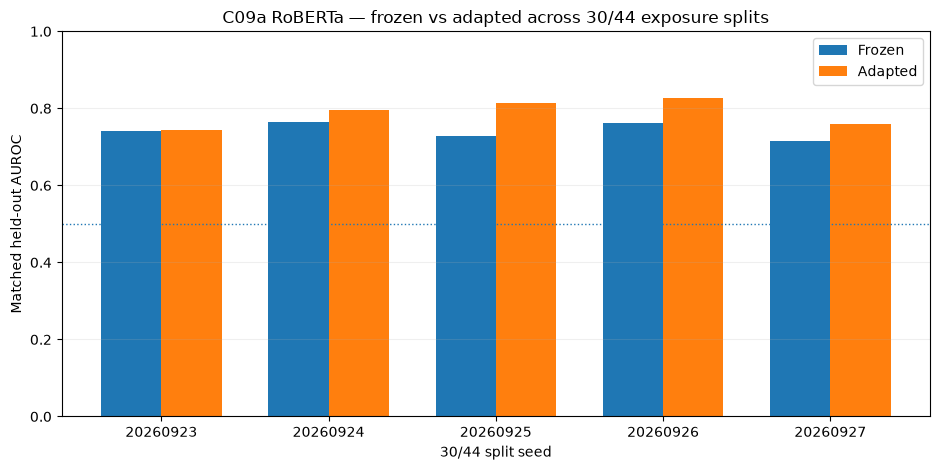

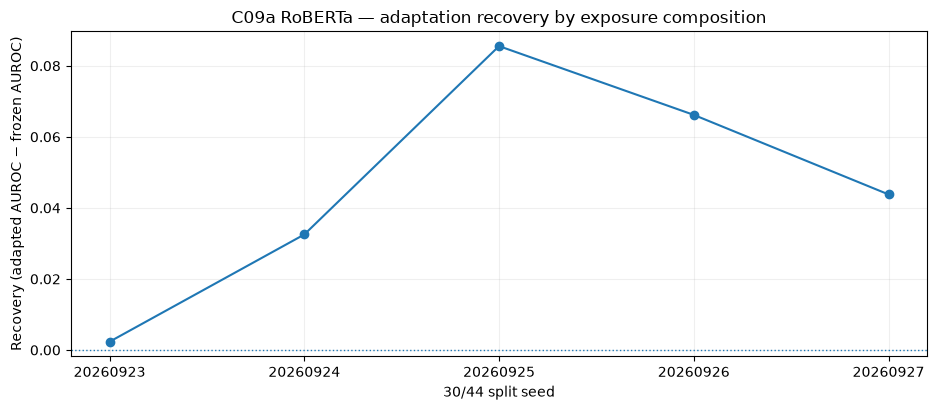

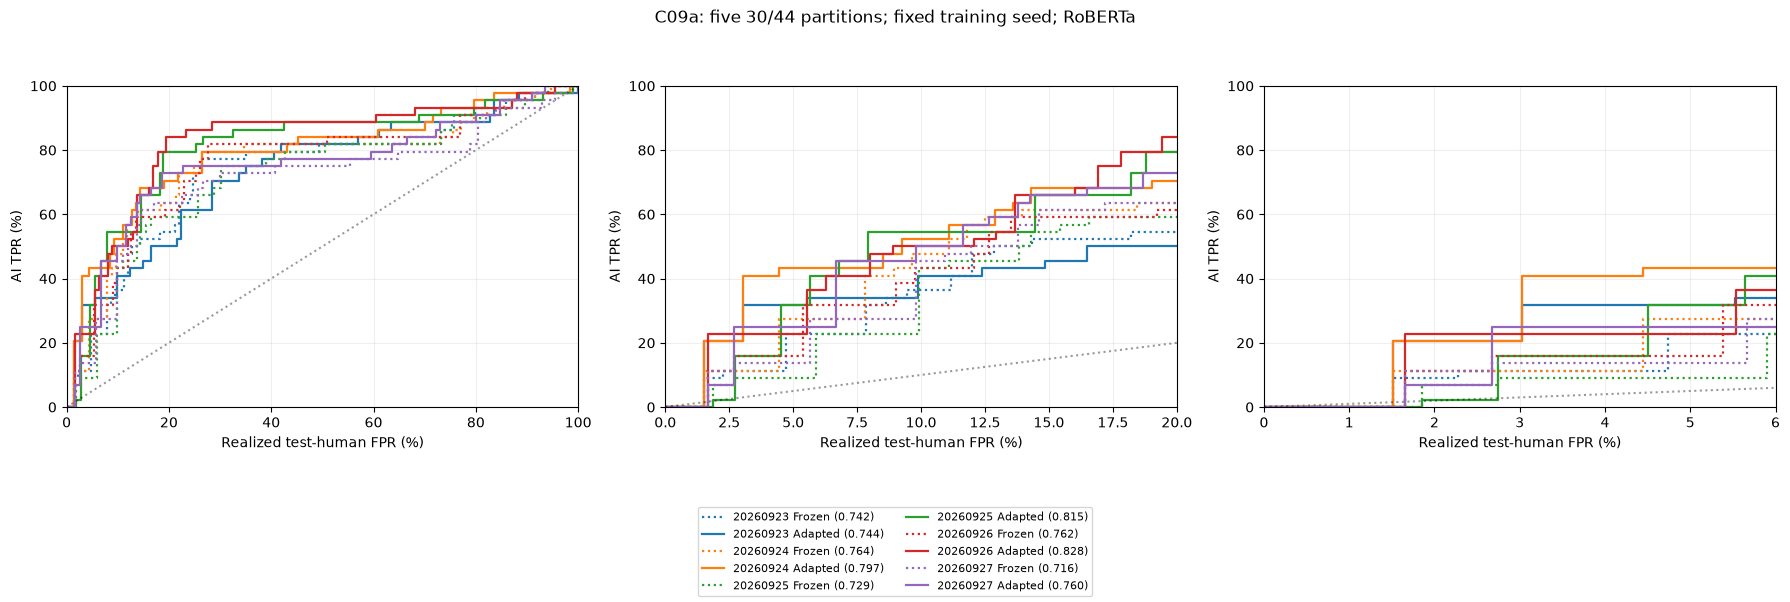

In [6]:
assert len(summary) == 5
assert summary.split_seed.tolist() == SPLIT_SEEDS

recovery_stats = pd.DataFrame([
    {"statistic": "mean",   "recovery": float(summary.recovery.mean())},
    {"statistic": "median", "recovery": float(summary.recovery.median())},
    {"statistic": "SD",     "recovery": float(summary.recovery.std(ddof=1))},
    {"statistic": "min",    "recovery": float(summary.recovery.min())},
    {"statistic": "max",    "recovery": float(summary.recovery.max())},
])
atomic_csv(recovery_stats, OUT / "recovery_stats.csv")

print("30/44 RoBERTa split sweep")
display(summary.round(6))
print("Recovery summary (sample SD)")
display(recovery_stats.round(6))

x = np.arange(len(summary))
w = 0.36

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.bar(x - w/2, summary.frozen_AUROC, width=w, label="Frozen")
ax.bar(x + w/2, summary.adapted_AUROC, width=w, label="Adapted")
ax.axhline(.5, linestyle=":", linewidth=1)
ax.set(
    xticks=x,
    xticklabels=summary.split_seed.astype(str),
    ylim=(0, 1),
    xlabel="30/44 split seed",
    ylabel="Matched held-out AUROC",
    title="C09a RoBERTa — frozen vs adapted across 30/44 exposure splits",
)
ax.legend()
ax.grid(axis="y", alpha=.2)
fig.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        FIG / f"RoBERTa_30of74_frozen_vs_adapted.{ext}",
        dpi=240,
        bbox_inches="tight",
    )
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(summary.split_seed.astype(str), summary.recovery, marker="o")
ax.axhline(0, linestyle=":", linewidth=1)
ax.set(
    xlabel="30/44 split seed",
    ylabel="Recovery (adapted AUROC − frozen AUROC)",
    title="C09a RoBERTa — adaptation recovery by exposure composition",
)
ax.grid(alpha=.2)
fig.tight_layout()

for ext in ["png", "pdf"]:
    fig.savefig(
        FIG / f"RoBERTa_30of74_recovery_by_split_seed.{ext}",
        dpi=240,
        bbox_inches="tight",
    )
plt.show()
plt.close(fig)
# All curves use their own matched human weights and validation-calibrated thresholds.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.tab10(np.arange(len(SPLIT_SEEDS)))
for seed, color in zip(SPLIT_SEEDS, colors):
    stairs = pd.read_csv(OUT / f'split_seed_{seed}' / 'TPR_staircase.csv')
    for kind, style in [('Frozen', ':'), ('Adapted', '-')]:
        st = stairs.loc[stairs.model.eq(kind)]
        value = summary.set_index('split_seed').loc[seed, kind.lower() + '_AUROC']
        for ax in axes:
            ax.step(100*st.test_FPR, 100*st.TPR, where='post', color=color,
                    ls=style, lw=1.6, label=f'{seed} {kind} ({value:.3f})')
for ax, limit in zip(axes, [100, 20, 6]):
    ax.plot([0, limit], [0, limit], 'k:', alpha=.4)
    ax.set(xlim=(0, limit), ylim=(0, 100), xlabel='Realized test-human FPR (%)', ylabel='AI TPR (%)')
    ax.grid(alpha=.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=8)
fig.suptitle('C09a: five 30/44 partitions; fixed training seed; RoBERTa')
fig.tight_layout(rect=[0,.22,1,.94])
for ext in ['png','pdf']:
    fig.savefig(FIG / f'RoBERTa_30of74_staircases.{ext}', dpi=240, bbox_inches='tight')
plt.show(); plt.close(fig)


## 6. Interpretation guardrails

This experiment diagnoses **split sensitivity at one fixed exposure size (30/74)**. It must **not** be used to claim a smooth exposure-response curve.

For a compact automated readout, the cell below uses explicit descriptive thresholds chosen to match the scale of the motivating C09 result:

- `near zero`: `|recovery| <= 0.03`
- `strong positive`: `recovery >= 0.10`

These are descriptive thresholds, not hypothesis-test cutoffs. The raw five recoveries and their spread remain the primary result.

Both exposure membership and its held-out complement change. This diagnoses sensitivity of the overall 30/44 experiment, not solely a causal effect of the exposed examples. The five held-out sets overlap; their spread is descriptive, not five independent population replicates. Fixed RNG settings reduce training variability but do not guarantee bitwise reproducibility across hardware/runtime changes. Rerunning can reveal instability or data/protocol mismatches; it cannot prove the absence of every implementation error.

In [7]:
NEAR_ZERO = 0.03
STRONG_POSITIVE = 0.10

orig = summary.loc[summary.split_seed.eq(20260923)].iloc[0]
new = summary.loc[~summary.split_seed.eq(20260923)].copy()

orig_near_zero = abs(orig.recovery) <= NEAR_ZERO
n_new_strong = int((new.recovery >= STRONG_POSITIVE).sum())
n_all_near_zero = int((summary.recovery.abs() <= NEAR_ZERO).sum())

wide = (
    summary.recovery.max() - summary.recovery.min() >= 0.15
    or (
        (summary.recovery.abs() <= NEAR_ZERO).any()
        and (summary.recovery >= STRONG_POSITIVE).any()
    )
)

if orig_near_zero and n_new_strong >= 3:
    interpretation = (
        "Most new split seeds show strong positive recovery while the original "
        "20260923 split remains near zero. This supports treating the original "
        "30/44 result as split-sensitive/anomalous."
    )
elif wide:
    interpretation = (
        "Recoveries vary widely across the five 30/44 partitions. RoBERTa "
        "adaptation/evaluation is split sensitive under this fixed training protocol."
    )
elif n_all_near_zero >= 4:
    interpretation = (
        "All or most 30/44 recoveries remain near zero. Split membership alone "
        "probably does not explain the earlier 20/40 rebound; training stochasticity "
        "is a natural next hypothesis to test."
    )
else:
    interpretation = (
        "The five splits give a mixed result that does not cleanly support one of "
        "the descriptive qualitative patterns. Report the individual recoveries "
        "and distribution without forcing a monotonic exposure interpretation."
    )

print(interpretation)
print(
    "\nDo not infer a smooth exposure-response curve from C09a: "
    "the exposure size is fixed at 30 and only exposure composition varies."
)

atomic_json(
    OUT / "interpretation.json",
    {
        "near_zero_threshold": NEAR_ZERO,
        "strong_positive_threshold": STRONG_POSITIVE,
        "original_seed_recovery": float(orig.recovery),
        "new_seeds_strong_positive_count": n_new_strong,
        "all_splits_near_zero_count": n_all_near_zero,
        "recovery_range": float(summary.recovery.max() - summary.recovery.min()),
        "interpretation": interpretation,
        "guardrail": (
            "C09a varies only 30/44 exposure composition; "
            "do not claim a smooth exposure-response curve."
        ),
    },
)

The five splits give a mixed result that does not cleanly support one of the descriptive qualitative patterns. Report the individual recoveries and distribution without forcing a monotonic exposure interpretation.

Do not infer a smooth exposure-response curve from C09a: the exposure size is fixed at 30 and only exposure composition varies.


## Saved artifacts

Top level:

- `split_sweep_summary.csv`
- `recovery_stats.csv`
- `case_roles_all.csv`
- `inputs_contract.json`
- `interpretation.json`
- `figures/RoBERTa_30of74_frozen_vs_adapted.{png,pdf}`
- `figures/RoBERTa_30of74_recovery_by_split_seed.{png,pdf}`

Per `split_seed_<seed>/`:

- `split_manifest.json` — exact exposed/held-out case IDs, source IDs, text hashes, and permutation
- `case_roles.csv`
- `protocol.json`
- `training/` — resumable Hugging Face Trainer checkpoints
- `best_model/` — selected adapted checkpoint
- `training_complete.json`
- `scores/adapted_attack/` and `scores/adapted_humans/` — per-text resumable score cache
- `adapted_heldout_scores.csv`
- `adapted_human_scores.csv`
- `heldout_scores.csv` — frozen/adapted scores and per-case AUROC contributions
- frozen/adapted validation/test human reference exports with held-out-genre weights
- `TPR_staircase.csv`
- `summary.csv`
- `split_complete.json`

The notebook never fits to or selects checkpoints using the 44 held-out NS10 cases.
Additional artifacts: per-split `score_contract.json` and `figures/RoBERTa_30of74_staircases.{png,pdf}`.